# 4. Мощность

Какой эффект на долю завершивших каждый эксперимент мог заметить и сколько учеников нужно, чтобы заметить +3 п.п.

- MDE - минимальный обнаружимый эффект при двустороннем α = 0,05 и мощности 0,8. Базовая доля - доля завершивших
  в контроле, дисперсия обеих групп берётся по ней.
- +3 п.п. - продуктовое допущение, выбранное до расчёта эффектов: прирост, ради которого имеет смысл менять задание
  для всех учеников. Размер групп для него - по формуле Флейса.
- В решениях значимость считается после поправки BH, её порог для отдельного теста где-то между 0,05/21 и 0,05.
  Поэтому MDE при α = 0,05 - оптимистичная оценка, рядом для сравнения MDE при пороге Bonferroni 0,05/21.
- Мощность по наблюдённому эффекту (post-hoc) не считаю: она однозначно выражается через p-value и ничего к нему
  не добавляет.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, db, effects, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = db.connect()
TARGET = 0.03

In [2]:
wide = effects.completion_wide(con)
pw = wide[wide["sample"] == "all"].drop(columns="sample").reset_index(drop=True)
pw["rate_c"] = pw.done_c / pw.n_c
pw["mde"] = [stats.mde_two_prop(p, ne, nc) for p, ne, nc in zip(pw.rate_c, pw.n_e, pw.n_c)]
pw["mde_bonf"] = [stats.mde_two_prop(p, ne, nc, alpha=0.05 / 21) for p, ne, nc in zip(pw.rate_c, pw.n_e, pw.n_c)]
pw["headroom"] = 1 - pw.rate_c
pw["n_needed"] = [np.ceil(stats.n_two_prop(p, TARGET)) for p in pw.rate_c]
pw["n_actual"] = (pw.n_c + pw.n_e) / 2
pw["times_more"] = pw.n_needed / pw.n_actual
pw["in_decisions"] = pw.experiment_id != effects.EXCLUDED
pw[["experiment_id", "n_c", "n_e", "rate_c", "headroom", "mde", "mde_bonf", "n_needed", "times_more", "in_decisions"]].round(3)

,experiment_id,n_c,n_e,rate_c,headroom,mde,mde_bonf,n_needed,times_more,in_decisions
0,226210,607,578,0.680,0.320,0.076,0.105,3694.0,6.235,True
1,237447,329,363,0.985,0.015,0.026,0.036,NaN,NaN,True
2,241501,188,193,0.894,0.106,0.089,0.123,1448.0,7.601,True
3,241622,338,289,0.882,0.118,0.073,0.100,1616.0,5.155,True
4,243393,910,887,0.733,0.267,0.058,0.081,3287.0,3.658,True
5,246482,225,232,0.733,0.267,0.116,0.161,3284.0,14.372,True
6,246627,279,235,0.724,0.276,0.111,0.154,3363.0,13.086,True
7,246647,264,274,0.845,0.155,0.088,0.121,2103.0,7.818,True
8,250476,193,209,0.891,0.109,0.087,0.121,1482.0,7.373,True
9,255116,258,276,0.822,0.178,0.093,0.129,2382.0,8.921,True


In [3]:
dec = pw[pw.in_decisions]
print("экспериментов в решениях:", len(dec))
print("MDE при α = 0,05: медиана", round(100 * dec.mde.median(), 1), "п.п., от", round(100 * dec.mde.min(), 1),
      "до", round(100 * dec.mde.max(), 1))
print("MDE больше 3 п.п.:", (dec.mde > TARGET).sum(), " при пороге Bonferroni:", (dec.mde_bonf > TARGET).sum())
print("MDE больше запаса до 100% (улучшение заметить нельзя в принципе):", (dec.mde > dec.headroom).sum())
print("+3 п.п. невозможно, контроль уже выше 97%:", dec.n_needed.isna().sum())
print("медиана: нужно учеников в группе в", round(dec.times_more.median(), 1), "раза больше, чем было")

экспериментов в решениях: 21
MDE при α = 0,05: медиана 7.6 п.п., от 2.6 до 12.5
MDE больше 3 п.п.: 20  при пороге Bonferroni: 21
MDE больше запаса до 100% (улучшение заметить нельзя в принципе): 3
+3 п.п. невозможно, контроль уже выше 97%: 2
медиана: нужно учеников в группе в 6.2 раза больше, чем было


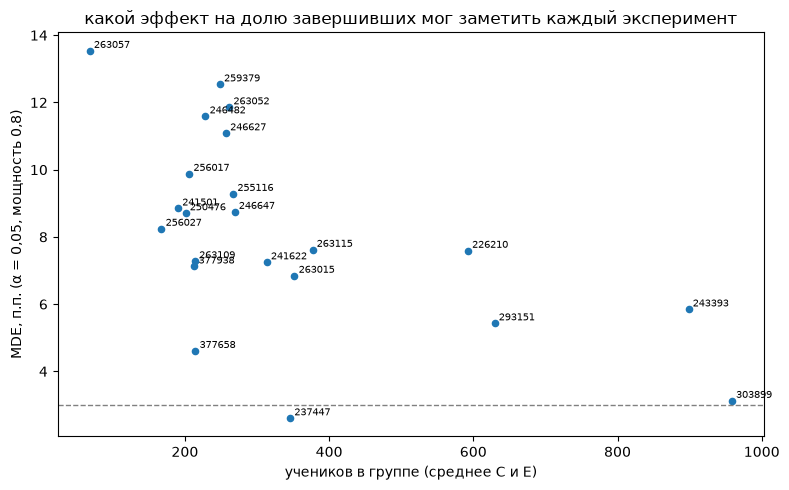

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
d = pw.sort_values("mde")
ax.scatter(d.n_actual, 100 * d.mde, s=20)
for r in d.itertuples():
    ax.annotate(str(r.experiment_id), (r.n_actual, 100 * r.mde), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.axhline(100 * TARGET, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("учеников в группе (среднее C и E)")
ax.set_ylabel("MDE, п.п. (α = 0,05, мощность 0,8)")
ax.set_title("какой эффект на долю завершивших мог заметить каждый эксперимент")
plt.tight_layout()

## Итог

- Почти все эксперименты слишком малы для эффекта в 3 п.п. MDE при α = 0,05 и мощности 0,8 - от 2,6 до 12,5 п.п.,
  медиана 7,6. Больше 3 п.п. он в 20 экспериментах из 21, при пороге Bonferroni - во всех 21.
- Единственный эксперимент с MDE меньше 3 п.п. - 237447 (2,6 п.п.), но там в контроле завершают 98,5%: расти
  некуда, запас всего 1,5 п.п. Ещё в 377658 и 256027 MDE больше запаса до 100%, то есть улучшение там нельзя было
  заметить в принципе.
- Для +3 п.п. нужно от 809 до 4 315 учеников в группе, в медиане в 6,2 раза больше, чем было. В 237447 и 377658
  +3 п.п. невозможны: контроль уже выше 97%.
- 303899 - пограничный случай: MDE 3,1 п.п., а по формуле для +3 п.п. учеников хватает (809 при 958). Расхождение
  из-за дисперсии: MDE считается по дисперсии контроля, а формула Флейса учитывает, что у доли 96,6% дисперсия
  меньше.
- Отсюда ожидание на этап 6: незначимый результат здесь почти всегда значит «мало данных», а не «эффекта нет».
  «Не выкатывать» по правилу получится только там, где интервал целиком ниже +3 п.п.